# Computer Vision — tracking a ball with a Haar cascade + Kalman filter

A per-frame **object detector** reports where the target is — a noisy centroid $(x, y)$, and
sometimes *nothing* (occlusion, motion blur, a miss). A constant-velocity **Kalman filter**
(`kalman.apps.vision.DetectionModel`) turns that ragged stream into a smooth, gap-free track:
it denoises the detector's jitter and **coasts** (predict-only) through the misses.

This is one concrete example. A real **Haar cascade** detects a rolling ball in the VOT "ball"
clip; we look at exactly **what goes into** the Kalman filter (the centroids) and **what comes
out** (the smoothed, occlusion-robust track).

In [1]:
%pip install numpy matplotlib opencv-python-headless > /dev/null
import warnings; warnings.filterwarnings("ignore")
import os, tempfile, zipfile, urllib.request
import numpy as np, matplotlib.pyplot as plt, cv2
from matplotlib.patches import Rectangle
import kalman; kalman.set_debug(0)
from kalman.apps.vision import DetectionModel


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
# Fetch the VOT \"ball\" clip + its trained Haar-cascade detector (Kaggle, no auth needed).
CACHE = tempfile.gettempdir()
DATA  = os.path.join(CACHE, "vot_dataset")
ZIP   = os.path.join(CACHE, "videos-for-object-tracking.zip")
URL   = "https://www.kaggle.com/api/v1/datasets/download/angevalli/videos-for-object-tracking"
try:
    if not (os.path.exists(ZIP) and os.path.getsize(ZIP) > 1_000_000):
        req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=120) as r, open(ZIP, "wb") as f:
            f.write(r.read())
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(DATA)
    VIDEO   = os.path.join(DATA, "Test-Videos", "VOT-Ball.mp4")
    CASCADE = os.path.join(DATA, "ball_cascade.xml")
    have = os.path.exists(VIDEO) and os.path.exists(CASCADE)
except Exception as e:
    have = False; print("could not fetch dataset:", e)
print("dataset ready:", have)

dataset ready: True


## Step 1 — the detector: Haar cascade → centroid (the Kalman **input**)

We run a trained **Haar cascade** on every frame. When it fires we take the centroid of the
ball's box, $(x, y)$; when it misses we record `NaN`. That `(N, 2)` array — two numbers per
frame, `NaN` on a miss — is the **entire input** to the Kalman filter. It never sees a pixel.

VOT-Ball: 602 frames 320x240;  cascade found the ball in 382/602 (63%)  — the rest are NaN (misses)

first rows fed to the Kalman filter  (x, y):
[[223.5 138.5]
 [225.5 136.5]
 [  nan   nan]
 [225.  140. ]
 [224.  139. ]
 [224.  142. ]]


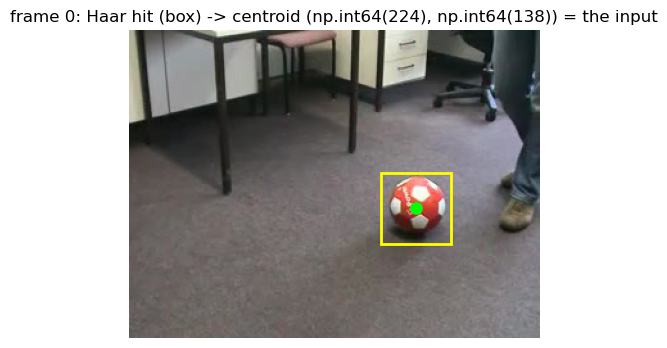

In [3]:
def detect_centroid(cascade, frame):
    """Haar-cascade ball detection -> (centroid (x,y), box (x,y,w,h)), or (None, None) on a miss."""
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    hits = cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=4, minSize=(15, 15))
    if len(hits) == 0:
        return None, None
    x, y, w, h = max(hits, key=lambda b: b[2] * b[3])
    return (x + w / 2.0, y + h / 2.0), (x, y, w, h)

if have:
    cascade = cv2.CascadeClassifier(CASCADE)
    cap = cv2.VideoCapture(VIDEO); frames, dets, boxes = [], [], []
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        c, b = detect_centroid(cascade, fr)
        dets.append([np.nan, np.nan] if c is None else list(c)); boxes.append(b)
    cap.release()
    dets = np.array(dets, float)
    H, W = frames[0].shape[:2]
    n_det = int(np.sum(~np.isnan(dets[:, 0])))
    print(f"VOT-Ball: {len(frames)} frames {W}x{H};  cascade found the ball in "
          f"{n_det}/{len(frames)} ({100*n_det/len(frames):.0f}%)  — the rest are NaN (misses)")
    print("\nfirst rows fed to the Kalman filter  (x, y):")
    print(np.round(dets[:6], 1))

    k = next(i for i, b in enumerate(boxes) if b is not None)
    x, y, w, h = boxes[k]
    fig, ax = plt.subplots(figsize=(6, 4)); ax.imshow(frames[k])
    ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="yellow", lw=2))
    ax.plot(x + w / 2, y + h / 2, "o", color="lime", ms=8)
    ax.set_title(f"frame {k}: Haar hit (box) -> centroid {tuple(np.round(dets[k]).astype(int))} = the input")
    ax.axis("off"); plt.show()

## Step 2 — the Kalman filter: centroids in → smoothed track out (the **output**)

`DetectionModel` is a constant-velocity tracker on $x=[x, y, v_x, v_y]$ that observes $(x, y)$.
We feed it the centroid stream; it returns a smooth track and **coasts** through the `NaN`
gaps (predict-only), its uncertainty $\sigma$ growing until the ball is re-detected.

In [ ]:
if have:
    model = DetectionModel("ball", fs=25, frame=(W, H),
                           measurement_uncertainty=8.0, process_uncertainty=60.0)
    x0 = next(d for d in dets if not np.isnan(d[0]))
    model.initial_state([x0[0], x0[1], 0, 0])
    rec = model.filter(dets)                      # <-- centroids in, smoothed state out

    SHOW_TRAIL = False   # this clip is handheld: pixel-position history mixes camera + ball
                         # motion and looks like a tangle. Set True for a fixed/tripod camera.

    gap = np.isnan(dets[:, 0])
    show = np.linspace(20, len(frames) - 20, 6).astype(int)
    fig, axes = plt.subplots(2, 3, figsize=(13, 7))
    for ax, kf in zip(axes.ravel(), show):
        ax.imshow(frames[kf])
        px, py = rec.xk[kf, 0], rec.xk[kf, 1]
        sx, sy = np.sqrt(rec.Pk[kf, 0, 0]), np.sqrt(rec.Pk[kf, 1, 1])
        bw, bh = max(16, 3 * sx), max(16, 3 * sy)
        # ±3σ bounding box around the Kalman position
        ax.add_patch(Rectangle((px - bw, py - bh), 2 * bw, 2 * bh, fill=False, edgecolor="red", lw=2))
        # trajectory trail up to this frame (optional — see SHOW_TRAIL above)
        if SHOW_TRAIL:
            ax.plot(rec.xk[:kf + 1, 0], rec.xk[:kf + 1, 1], color="cyan", lw=1.5, alpha=0.75)
        # current Kalman position
        ax.plot(px, py, "o", color="red", ms=6, zorder=5)
        # detector centroid (green dot when not occluded)
        if not gap[kf]:
            ax.plot(dets[kf, 0], dets[kf, 1], "o", color="lime", ms=7, zorder=6)
        ax.axis("off"); ax.set_title(f"frame {kf}" + ("  — coasting" if gap[kf] else ""))
    fig.suptitle("Kalman OUTPUT: red box = ±3σ, red dot = tracked position, "
                 "green = detector input"
                 + (", cyan = trajectory trail" if SHOW_TRAIL else ""),
                 fontweight="bold")
    fig.tight_layout(); plt.show()

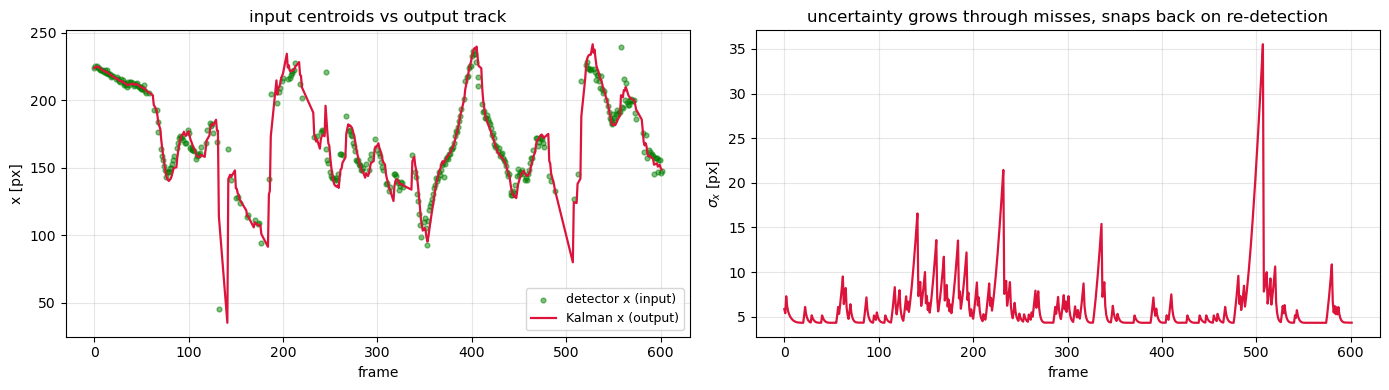

In [5]:
if have:
    m = ~np.isnan(dets[:, 0])
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].scatter(np.where(m)[0], dets[m, 0], s=12, c="green", alpha=0.5, label="detector x (input)")
    ax[0].plot(rec.xk[:, 0], "crimson", lw=1.6, label="Kalman x (output)")
    ax[0].set_xlabel("frame"); ax[0].set_ylabel("x [px]"); ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3)
    ax[0].set_title("input centroids vs output track")
    ax[1].plot(np.sqrt(rec.Pk[:, 0, 0]), "crimson", lw=1.6)
    ax[1].set_xlabel("frame"); ax[1].set_ylabel(r"$\sigma_x$ [px]"); ax[1].grid(alpha=0.3)
    ax[1].set_title("uncertainty grows through misses, snaps back on re-detection")
    fig.tight_layout(); plt.show()

## Takeaway — single-object tracking

- **Input**: the detector's centroid $(x, y)$ each frame — `NaN` on a miss. Two numbers; the filter never sees a pixel.
- **Output**: a smooth, gap-free track — denoised jitter + coasting (predict-only, $\sigma$ growing) through misses, snapping back on re-detection. The red **±3σ box** expands during coasting.
- **Trajectory trail** (cyan) is *optional* — toggle `SHOW_TRAIL` above / pass `trail=` to the interactive player. It's only meaningful for a fixed/tripod camera; on handheld footage the pixel-position history mixes camera pan with the target's own motion.
- **Interactive player** (next cell): scrub or play the full video with the box updating in real time.

Multi-object tracking with IoU/Hungarian association follows in **Step 3** (synthetic scene) and **Step 4** (MOT16 benchmark).

### Interactive player — scrub through the full video with tracking overlaid

`model.plot(rec, interactive=True, frames=…, detections=…, trail=…)` renders each frame with:
- **Red dot + box** — estimated position ± 3σ (box expands during coasting)
- **Green dot** — raw detector centroid (hidden when detector missed)
- **Cyan trail** *(optional, `trail=True`)* — Kalman position history up to the current frame.
  Off by default here: this clip is **handheld**, so a pixel-position trail mixes camera pan
  with the ball's own motion and just looks like a tangle (see the `SHOW_TRAIL` toggle in the
  Step 2 cell above). Turn it on for fixed/tripod footage, where the trail is meaningful.

In [ ]:
if have:
    model.plot(rec, interactive=True, frames=frames, detections=dets,
              sigma=3.0, interval=60, trail=SHOW_TRAIL)

## Step 3 — Multi-object tracking (SORT)

**SORT** (*Simple Online and Realtime Tracking*, Bewley et al. 2016) extends single-object filtering
to a fleet of objects by coupling a Kalman filter with **IoU/Hungarian assignment**:

1. Each existing track is **predicted** one step forward.
2. Detector boxes are **matched** to predicted boxes by IoU + Hungarian algorithm.
3. Matched tracks are **updated**; unmatched detections **birth** new tracks; tracks unseen
   for `max_age` frames are **retired**.
4. A track is only **reported** once it has accumulated `min_hits` hits (avoids false alarms
   on the very first frame).

`kalman.apps.vision.SortTracker` wraps this loop; `synthetic_multi` generates a reproducible
3-object crossing scene with one occlusion gap to exercise coasting.

Synthetic scene: 120 frames, up to 3 simultaneous tracks
Track IDs used: [0, 1, 2, 3]


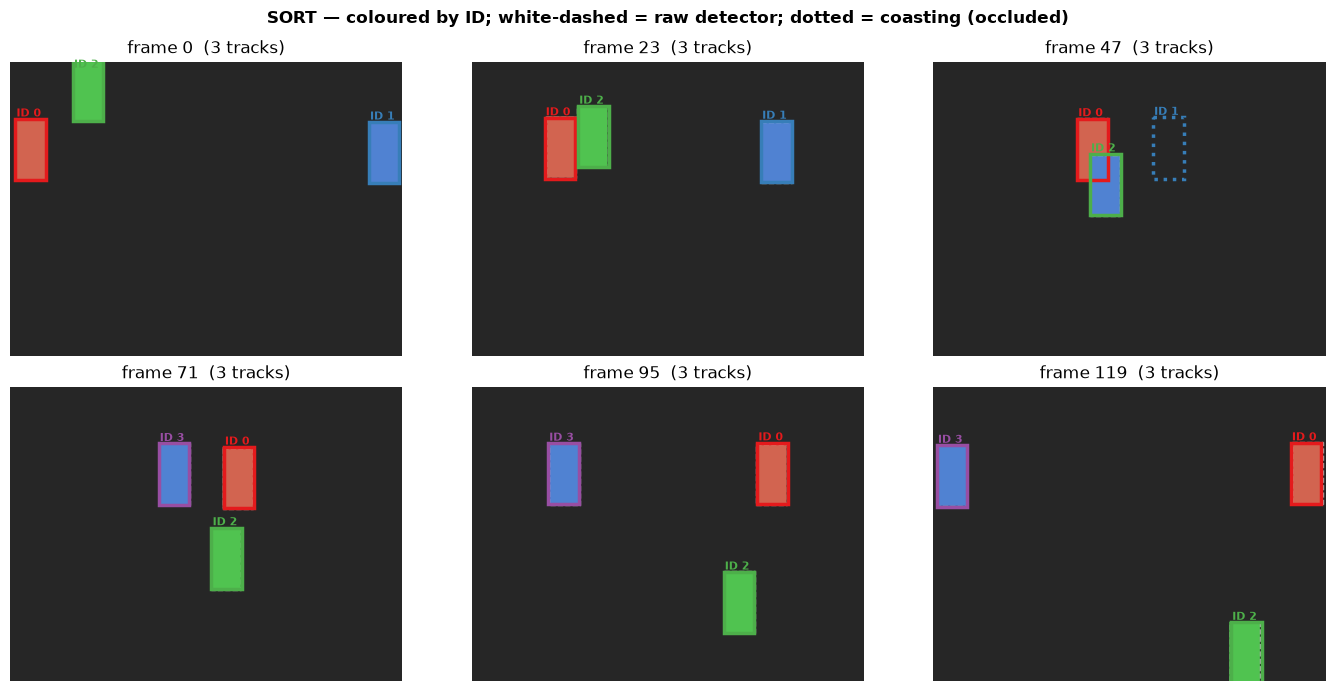

In [2]:
from kalman.apps.vision import SortTracker, synthetic_multi

TRACK_COLORS = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628"]

scene   = synthetic_multi(n_frames=120, frame=(640, 480), seed=42)
tracker = SortTracker(max_age=12, min_hits=2, iou_threshold=0.3, frame=(640, 480))
results = tracker.run(scene)

print(f"Synthetic scene: {len(scene)} frames, up to {max(len(r) for r in results)} simultaneous tracks")
print(f"Track IDs used: {sorted({tb.id for frame in results for tb in frame})}")

# ── Render simple "video frames": dark background + filled blobs per detected object ──
OBJ_COLORS_BGR = [(210, 100, 80), (80, 130, 210), (80, 195, 80), (200, 80, 200)]

def render_frame(det_boxes, h=480, w=640):
    img = np.full((h, w, 3), 38, dtype=np.uint8)   # dark background
    for i, box in enumerate(det_boxes):
        x1, y1, x2, y2 = [int(round(v)) for v in box]
        x1, y1, x2, y2 = max(0,x1), max(0,y1), min(w,x2), min(h,y2)
        if x2 > x1 and y2 > y1:
            img[y1:y2, x1:x2] = OBJ_COLORS_BGR[i % len(OBJ_COLORS_BGR)]
    return img

rendered = [render_frame(det_boxes) for det_boxes in scene]

# ── 6-frame summary grid ──────────────────────────────────────────────────────
show = np.linspace(0, len(scene) - 1, 6).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, kf in zip(axes.ravel(), show):
    ax.imshow(rendered[kf])
    # raw detections (dashed white outline)
    for box in scene[kf]:
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               fill=False, edgecolor="white", lw=1.0, ls="--", alpha=0.6))
    # Kalman tracks (coloured by ID; dotted when coasting)
    for tb in results[kf]:
        col = TRACK_COLORS[tb.id % len(TRACK_COLORS)]
        x1, y1, x2, y2 = tb.box
        ls = ":" if tb.coasting else "-"
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               fill=False, edgecolor=col, lw=2.5, ls=ls))
        ax.text(x1 + 2, max(y1 - 4, 10), f"ID {tb.id}",
                color=col, fontsize=8, fontweight="bold")
    ax.set_xlim(0, 640); ax.set_ylim(480, 0)
    ax.set_title(f"frame {kf}  ({len(results[kf])} tracks)")
    ax.axis("off")

fig.suptitle("SORT — coloured by ID; white-dashed = raw detector; dotted = coasting (occluded)",
             fontweight="bold")
fig.tight_layout(); plt.show()

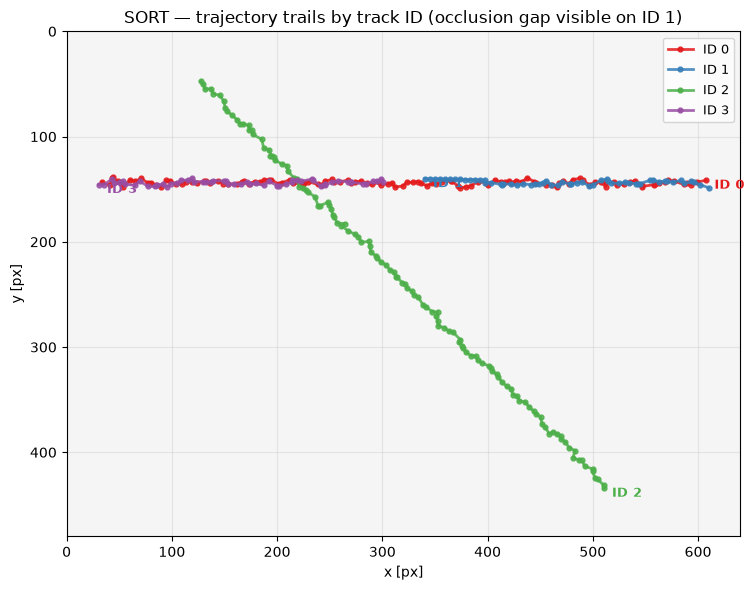

In [3]:
# ── Trajectory trails: full history per track ID ──────────────────────────────
from collections import defaultdict

# Accumulate positions per ID across all frames
trails = defaultdict(list)
for kf, frame_tracks in enumerate(results):
    for tb in frame_tracks:
        cx = (tb.box[0] + tb.box[2]) / 2.0
        cy = (tb.box[1] + tb.box[3]) / 2.0
        trails[tb.id].append((kf, cx, cy))

fig, ax = plt.subplots(figsize=(10, 6))
canvas = np.full((480, 640, 3), 245, dtype=np.uint8)
ax.imshow(canvas, vmin=0, vmax=255)
for tid, pts in trails.items():
    pts = np.array(pts)      # (K, 3): frame, cx, cy
    col = TRACK_COLORS[tid % len(TRACK_COLORS)]
    ax.plot(pts[:, 1], pts[:, 2], "-o", color=col, lw=2.0, ms=3.5,
            alpha=0.85, label=f"ID {tid}")
    ax.annotate(f"ID {tid}", (pts[-1, 1], pts[-1, 2]),
                fontsize=9, color=col, fontweight="bold",
                xytext=(6, -6), textcoords="offset points")

ax.set_xlim(0, 640); ax.set_ylim(480, 0)
ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
ax.set_title("SORT — trajectory trails by track ID (occlusion gap visible on ID 1)")
ax.legend(fontsize=9); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.show()

## Step 4 — MOT16 benchmark (CLEAR-MOT)

We now score **the same `SortTracker`** on the real **MOT16** pedestrian benchmark using its
own published detections — so the Kalman filter gets exactly the input it would see in
production.

Key CLEAR-MOT metrics:
| Metric | Meaning |
|--------|---------|
| **MOTA** | Multi-Object Tracking Accuracy — combines FP, FN, and ID switches |
| **MOTP** | Precision — mean overlap of matched pairs (motmetrics reports as distance, so overlap = 1 − MOTP) |
| **IDF1** | F1 over ID-consistent detections |
| **MT / ML** | Fraction of ground-truth tracks *mostly tracked* / *mostly lost* |

SORT on MOT16 reaches MOTA ≈ 33 % with the published DPM detections (paper: Bewley et al., 2016).

In [ ]:
%pip install motmetrics > /dev/null

# ── Download MOT16 training set (Kaggle, no auth needed) ──────────────────────
MOT16_ZIP = os.path.join(CACHE, "mot16.zip")
MOT16_DIR = os.path.join(CACHE, "MOT16")
MOT16_URL = "https://www.kaggle.com/api/v1/datasets/download/takshmandar/mot16-dataset"

try:
    if not (os.path.exists(MOT16_ZIP) and os.path.getsize(MOT16_ZIP) > 10_000_000):
        print("Downloading MOT16 (~180 MB) …")
        req = urllib.request.Request(MOT16_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=300) as r, open(MOT16_ZIP, "wb") as f:
            f.write(r.read())
        print("download complete")
    with zipfile.ZipFile(MOT16_ZIP) as z:
        z.extractall(MOT16_DIR)
    have_mot16 = True
    print("MOT16 ready:", MOT16_DIR)
except Exception as e:
    have_mot16 = False
    print("Could not fetch MOT16:", e)

In [ ]:
import glob
from kalman.apps.vision import mot_sequences_from_root, evaluate_mot

if have_mot16:
    # auto-detect the train folder wherever the zip unpacked it
    train_dirs = sorted(glob.glob(os.path.join(MOT16_DIR, "**", "train"), recursive=True))
    if not train_dirs:
        train_dirs = sorted(glob.glob(os.path.join(MOT16_DIR, "**", "MOT16", "train"), recursive=True))

    if train_dirs:
        seqs = mot_sequences_from_root(train_dirs[0])
        print(f"Found {len(seqs)} sequences: {list(seqs.keys())}\n")

        summary = evaluate_mot(
            seqs,
            conf_thresh=0.0,          # use all DPM detections (canonical SORT setting)
            max_age=10, min_hits=3, iou_threshold=0.3,
        )

        # motmetrics' motp is a distance (1 - IoU), convert to overlap %
        if "motp" in summary.columns:
            summary["overlap%"] = (1.0 - summary["motp"]) * 100.0

        print("CLEAR-MOT results on MOT16-train (SORT, canonical settings):")
        try:
            from IPython.display import display
            display(summary.round(3))
        except ImportError:
            print(summary.round(3).to_string())
    else:
        print("Could not locate MOT16/train inside", MOT16_DIR)
        print(glob.glob(os.path.join(MOT16_DIR, "**"), recursive=True)[:20])

In [ ]:
if have_mot16 and train_dirs and seqs and "summary" in dir():
    # ── Per-sequence accuracy bar chart ───────────────────────────────────────
    # MOTA thresholds calibrated for DPM detectors (weak) on MOT16
    GOOD, OK = 35.0, 15.0   # [%]
    seq_df = summary.drop("OVERALL", errors="ignore").copy()
    mota_pct = seq_df["mota"].values * 100.0    # motmetrics MOTA ∈ (-∞, 1] → %
    idf1_pct = seq_df["idf1"].values * 100.0    # IDF1 ∈ [0, 1] → %
    names    = list(seq_df.index)

    bar_colors = ["#2ca02c" if m > GOOD else "#ff7f0e" if m > OK else "#d62728"
                  for m in mota_pct]
    acc_labels = ["GOOD ✓" if m > GOOD else "OK ~" if m > OK else "POOR ✗"
                  for m in mota_pct]

    x = np.arange(len(names)); w = 0.35
    fig, ax = plt.subplots(figsize=(max(10, len(names) * 1.7), 5))
    bars_m = ax.bar(x - w/2, mota_pct, w, color=bar_colors, edgecolor="black", lw=0.7,
                    label="MOTA [%]", alpha=0.87)
    ax.bar(x + w/2, idf1_pct, w, color="steelblue", edgecolor="black", lw=0.7,
           label="IDF1 [%]", alpha=0.75)

    for bar, m, lbl in zip(bars_m, mota_pct, acc_labels):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.6,
                f"{m:.1f}%\n{lbl}", ha="center", va="bottom", fontsize=8, fontweight="bold")

    ax.axhline(33.4, color="red",      ls="--", lw=1.4, label="SORT paper avg (DPM, 33.4 %)")
    ax.axhline(GOOD, color="#2ca02c",  ls=":",  lw=1.0, alpha=0.5, label=f"GOOD threshold ({GOOD} %)")
    ax.axhline(OK,   color="#d62728",  ls=":",  lw=1.0, alpha=0.5, label=f"POOR threshold ({OK} %)")

    ax.set_xticks(x); ax.set_xticklabels(names, fontsize=9)
    ax.set_ylabel("Score [%]")
    ax.set_ylim(0, max(np.nanmax(mota_pct), np.nanmax(idf1_pct)) * 1.20 + 5)
    ax.set_title("SORT accuracy per MOT16-train sequence  "
                 "| green > 35 % = GOOD, orange > 15 % = OK, red = POOR")
    ax.legend(fontsize=8, loc="upper left"); ax.grid(axis="y", alpha=0.25)
    fig.tight_layout(); plt.show()

In [ ]:
if have_mot16 and train_dirs and seqs:
    from kalman.apps.vision import mot_detections, SortTracker as _ST

    # Pick the first sequence and visualise per-frame track counts + trajectory trails
    seq_name = sorted(seqs)[0]
    det_path, gt_path = seqs[seq_name]
    det_by_frame = mot_detections(det_path, conf_thresh=0.0)

    tracker2 = _ST(max_age=10, min_hits=3, iou_threshold=0.3, fs=1.0)
    fmax = max(det_by_frame)
    frame_counts, all_ids = [], set()
    trails2 = defaultdict(list)
    for f in range(1, fmax + 1):
        tbs = tracker2.step(det_by_frame.get(f, np.empty((0, 4))))
        frame_counts.append(len(tbs))
        for tb in tbs:
            all_ids.add(tb.id)
            cx = (tb.box[0] + tb.box[2]) / 2.0
            cy = (tb.box[1] + tb.box[3]) / 2.0
            trails2[tb.id].append((f, cx, cy))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    # left: track count per frame
    axes[0].plot(range(1, fmax + 1), frame_counts, color="steelblue", lw=1.4)
    axes[0].set_xlabel("frame"); axes[0].set_ylabel("active confirmed tracks")
    axes[0].set_title(f"{seq_name} — active tracks per frame ({len(all_ids)} unique IDs)")
    axes[0].grid(alpha=0.3)
    # right: trajectory trails (first 20 tracks by birth order)
    ax2 = axes[1]
    for tid in sorted(trails2)[:20]:
        pts = np.array(trails2[tid])
        col = TRACK_COLORS[tid % len(TRACK_COLORS)]
        ax2.plot(pts[:, 1], pts[:, 2], "-", color=col, lw=1.0, alpha=0.7)
        ax2.plot(pts[0, 1], pts[0, 2], "o", color=col, ms=4)
    ax2.invert_yaxis()
    ax2.set_xlabel("x [px]"); ax2.set_ylabel("y [px]")
    ax2.set_title(f"{seq_name} — trajectory trails (first 20 IDs)")
    ax2.grid(alpha=0.3)
    fig.tight_layout(); plt.show()

### Interactive MOT16 player — SORT tracking on real video frames

Loads the first MOT16 sequence (actual camera frames), runs `SortTracker`, and plays an
animated scrub-player: coloured bounding boxes per confirmed track ID, trajectory trail
showing where each pedestrian has been, dotted box when the track is coasting (occluded).

In [ ]:
if have_mot16 and train_dirs and seqs:
    import glob as _glob
    from IPython.display import display as _display
    from kalman.helpers import animate as _kalman_animate

    # ── Load actual frames from the first MOT16 sequence ─────────────────────
    _seq = sorted(seqs)[0]
    _det_path, _ = seqs[_seq]
    _img_dir = os.path.join(os.path.dirname(os.path.dirname(_det_path)), "img1")
    _img_files = sorted(_glob.glob(os.path.join(_img_dir, "*.jpg")))

    if not _img_files:
        print(f"No frames in {_img_dir} — skipping interactive player")
    else:
        MAX_ANIM = 90
        _step = max(1, len(_img_files) // MAX_ANIM)
        _sel_i = list(range(0, len(_img_files), _step))[:MAX_ANIM]
        _frame_nums = [i + 1 for i in _sel_i]   # MOT16 frame IDs are 1-based

        print(f"Loading {len(_sel_i)} frames (every {_step}) from {_seq} …")
        _mot_imgs = [plt.imread(_img_files[i]) for i in _sel_i]
        H_mot, W_mot = _mot_imgs[0].shape[:2]

        # ── Run SORT over entire detection range, then select our frame subset ─
        _det_all = mot_detections(_det_path, conf_thresh=0.0)
        _tr = SortTracker(max_age=10, min_hits=3, iou_threshold=0.3, fs=1.0)
        _all_res = {f: _tr.step(_det_all.get(f, np.empty((0, 4)))) for f in range(1, max(_det_all) + 1)}
        _frame_res = [_all_res.get(fn, []) for fn in _frame_nums]

        # ── Pre-compute trails ────────────────────────────────────────────────
        _trails = defaultdict(list)
        for _j, _tbs in enumerate(_frame_res):
            for _tb in _tbs:
                _cx = (_tb.box[0] + _tb.box[2]) / 2.0
                _cy = (_tb.box[1] + _tb.box[3]) / 2.0
                _trails[_tb.id].append((_j, _cx, _cy))

        # Pre-create one trail Line2D per track ID
        _all_ids = sorted(_trails)
        fig2, ax2 = plt.subplots(figsize=(10, 6), dpi=65)
        ax2.imshow(_mot_imgs[0]); ax2.axis("off")
        ax2.set_xlim(0, W_mot); ax2.set_ylim(H_mot, 0)
        _title2 = ax2.set_title("")
        _trail_lines = {tid: ax2.plot([], [], "-", lw=1.2, alpha=0.60,
                                      color=TRACK_COLORS[tid % len(TRACK_COLORS)])[0]
                        for tid in _all_ids}
        _live_p, _live_t = [], []

        def _draw_mot(j):
            _im_obj = ax2.get_images()[0]
            _im_obj.set_data(_mot_imgs[j])
            for _p in _live_p: _p.remove()
            for _t in _live_t: _t.remove()
            _live_p.clear(); _live_t.clear()

            _tbs_j = _frame_res[j]
            _vis_ids = {_tb.id for _tb in _tbs_j}
            for _tb in _tbs_j:
                _col = TRACK_COLORS[_tb.id % len(TRACK_COLORS)]
                _x1, _y1, _x2, _y2 = _tb.box
                _rect = Rectangle((_x1, _y1), _x2 - _x1, _y2 - _y1,
                                  fill=False, edgecolor=_col, lw=2.0,
                                  ls=":" if _tb.coasting else "-")
                ax2.add_patch(_rect); _live_p.append(_rect)
                _txt = ax2.text(_x1 + 2, max(_y1 - 5, 10), f"ID {_tb.id}",
                                color=_col, fontsize=7, fontweight="bold")
                _live_t.append(_txt)

            for _tid, _tl in _trail_lines.items():
                _pts = [(_cx, _cy) for (_pj, _cx, _cy) in _trails[_tid] if _pj <= j]
                if _pts and _tid in _vis_ids:
                    _arr = np.array(_pts)
                    _tl.set_data(_arr[:, 0], _arr[:, 1])
                else:
                    _tl.set_data([], [])

            _title2.set_text(
                f"{_seq}  frame {_frame_nums[j]}  |  {len(_tbs_j)} confirmed tracks")
            return [_im_obj, _title2] + _live_p + _live_t + list(_trail_lines.values())

        _display(_kalman_animate(fig2, _draw_mot, frames=range(len(_mot_imgs)), interval=110))

## Summary

| Step | What it does | Key class / function |
|------|-------------|----------------------|
| 1 | Haar cascade → per-frame centroid (the Kalman **input**) | `cv2.CascadeClassifier` |
| 2 | Constant-velocity Kalman filter → smooth track + coasting | `DetectionModel` |
| 2b | Interactive scrub player with trajectory trail | `model.plot(interactive=True, frames=…)` |
| 3 | SORT multi-object: IoU/Hungarian + birth/death | `SortTracker`, `synthetic_multi` |
| 4 | CLEAR-MOT benchmark on real MOT16 sequences | `evaluate_mot`, `mot_sequences_from_root` |

The detector is always swappable — a Haar cascade, a blob detector, or a neural net — but the
tracking API never changes: boxes in → confirmed stable IDs out.